<a href="https://colab.research.google.com/github/Jayadeep19/pytorch/blob/master/5.%20sequential%20models/4_LSTM_Many_to_one.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LSTM Image classification

- In this notebook, I'll implement a many-to-one LSTM model to classify our favourite MNIST dataset.
- we will consider each image as a continuous sequence by splitting each image into continuous patches.
- At the end, we get one output per image.

In [1]:
import torch, torchvision
from torch import nn, optim
import torchvision.transforms as T
import torchvision.datasets as datasets
from torch.utils.data import dataloader, random_split
from torch.utils.data.dataset import Dataset


import numpy as np
from matplotlib import pyplot as plt
from tqdm.notebook import tqdm

## Data prep

In [2]:
#parameters for our model

lr = 0.0001
bs = 64
nepochs = 50

device_id = 0
device = torch.device( device_id if torch.cuda.is_available() else 'cpu')
print(device)

cuda:0


In [3]:
# let us calculate the mean and std for our dataset to normalise the dataset later
tem_dataset = datasets.MNIST(root ='./data', train = True, download = True, transform = T.ToTensor())
mean = tem_dataset.data.float().mean() / 255
std = tem_dataset.data.float().std() / 255
print('mean:',mean, 'std',std)
del tem_dataset

100%|██████████| 9.91M/9.91M [00:03<00:00, 2.56MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 134kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.29MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.8MB/s]


mean: tensor(0.1307) std tensor(0.3081)


In [4]:
# create a transform for our images

transform = T.Compose([T.ToTensor(),
                       T.Normalize(mean, std)])

In [5]:
# create the datasets and dataloaders just like we did in Convolutions section

train_data = datasets.MNIST(root ='./data', train = True, download = True, transform = transform)
test_data = datasets.MNIST(root ='./data', train = False, download = True, transform = transform)

# create a split for validationset
validation_split = 0.9

n_train_example = int(len(train_data) * validation_split)
n_validation_example = len(train_data) - n_train_example

# we can use pytorch's native method
# make the seed 42 to replicate same dataset everytime we run the script
generator = torch.Generator().manual_seed(42)
train_data, val_data = random_split(train_data, [n_train_example, n_validation_example], generator= generator)

In [6]:
train_data_loader = dataloader.DataLoader(train_data, shuffle=True, batch_size = bs)
val_data_loader = dataloader.DataLoader(val_data, batch_size = bs)
test_data_loader = dataloader.DataLoader(test_data, batch_size = bs)

In [25]:
img_iter = next(iter(train_data_loader))
test_imgs, test_labels = img_iter
print(test_imgs.shape, test_labels.shape)

torch.Size([64, 1, 28, 28]) torch.Size([64])


## Define the LSTM

- we pass the images as 28 patches with 28 pixels each

In [8]:
class LSTMclassifier(nn.Module):
  def __init__(self, input_size, hidden_size, output_size, num_layers = 1):
    super(LSTMclassifier, self).__init__()

    self.hidden = hidden_size
    self.num_layers = num_layers

    self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)

    self.fc = nn.Linear(hidden_size, output_size)

  def forward(self, x):
    '''
    x is already of shape [bs, channel, row, col]- [64,1,28,28]
    we just have to squeeze the channel to make it [bs, seq_len, input_size] - [64,28,28]
    '''

    x= x.squeeze(1)

    lstm_out, (h_n, c_n) = self.lstm(x)

    last_out = lstm_out[:,-1,:]

    out = self.fc(last_out)

    return out


  # def init_tensors(self, x):
  #   return torch.zeros(self.num_layers)



In [9]:
input_size = 28  #28 pixes per each row
seq_len = 28    #28 rows per image
hidden_size = 128
output_size = 10   #10 classes


In [10]:
model = LSTMclassifier(input_size, hidden_size, output_size).to(device)

print(model)

LSTMclassifier(
  (lstm): LSTM(28, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=10, bias=True)
)


## Train the model

In [11]:
loss_fn = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr = lr)

train_loss_log = []
val_loss_log = []

In [12]:
for epoch in tqdm(range(nepochs), desc = 'Epochs', leave = False):
  model.train()

  for data, target in tqdm(train_data_loader, desc = 'Training', leave= False):

    optimizer.zero_grad()

    data = data.to(device)
    target = target.to(device)

    predict = model(data)

    loss = loss_fn(predict, target)

    loss.backward()

    optimizer.step()

    train_loss_log.append(loss.item())

  #validation
  model.eval()
  val_acc = 0

  with torch.no_grad():
    for data, target in tqdm(val_data_loader, desc = 'Validation', leave = False):

      data = data.to(device)
      target = target.to(device)

      op = model(data)

      val_loss = loss_fn(op, target)

      val_loss_log.append(val_loss.item())
      val_acc += (op.argmax(dim=1) == target).sum()


print(f'The Final training loss of the model after training is: {train_loss_log[-1]}')
print(f'validation accuracy is: {(val_acc/(len(val_data))).item()}')

Epochs:   0%|          | 0/50 [00:00<?, ?it/s]

Training:   0%|          | 0/844 [00:00<?, ?it/s]

Validation:   0%|          | 0/94 [00:00<?, ?it/s]

Training:   0%|          | 0/844 [00:00<?, ?it/s]

Validation:   0%|          | 0/94 [00:00<?, ?it/s]

Training:   0%|          | 0/844 [00:00<?, ?it/s]

... (92 outputs left out)

Validation:   0%|          | 0/94 [00:00<?, ?it/s]

Training:   0%|          | 0/844 [00:00<?, ?it/s]

Validation:   0%|          | 0/94 [00:00<?, ?it/s]

The Final training loss of the model after training is: 0.004095273558050394
validation accuracy is: 0.9808333516120911


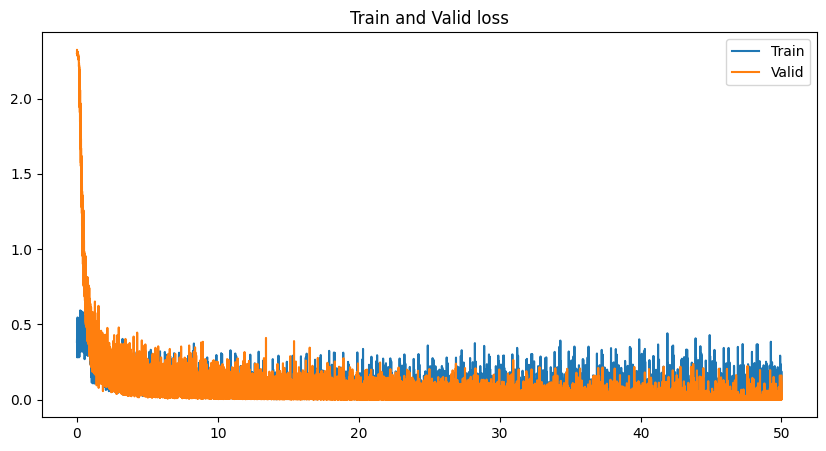

In [24]:
plt.figure(figsize=(10, 5))
plt.title("Train and Valid loss")
plt.plot(np.linspace(0, nepochs, len(val_loss_log)), val_loss_log)
plt.plot(np.linspace(0, nepochs, len(train_loss_log)), train_loss_log)
plt.legend(["Train", "Valid"])

## Test

In [45]:
# we can use the same test_iter object
sample_imgs = test_imgs[:8].to(device)
sample_labels = test_labels[:8].to(device)

with torch.no_grad():
  fx = model(sample_imgs)

predictions = torch.max(fx.detach().cpu(), dim = 1)


The predictions from the model are: tensor([7, 6, 6, 7, 2, 8, 7, 6])


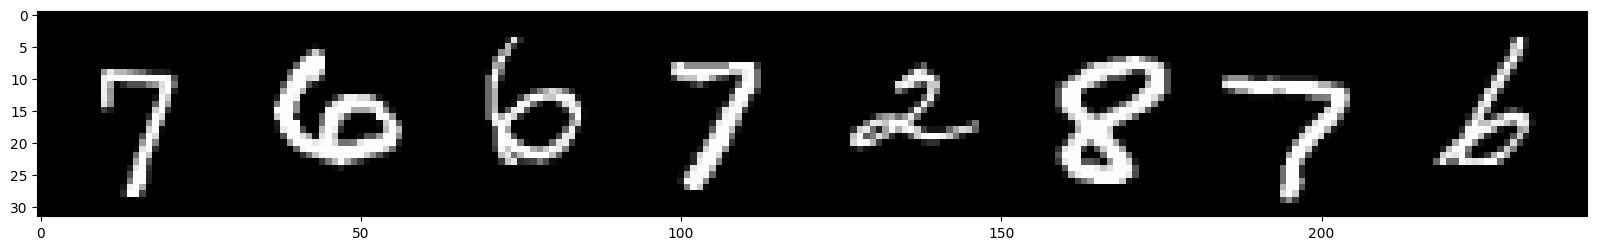

In [47]:
#plot:
plt.figure(figsize = (20,10))
out = torchvision.utils.make_grid(test_imgs[:8], 8, normalize=True)
plt.imshow(out.numpy().transpose((1, 2, 0)))
print(f'The predictions from the model are: {predictions.indices}')